In [1]:
%%time
%pip install pandas scikit-learn matplotlib
%pip install torch==2.8.0+cpu torchvision==0.23.0+cpu torchaudio==2.8.0+cpu \
    --index-url https://download.pytorch.org/whl/cpu


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.
CPU times: total: 109 ms
Wall time: 4.74 s



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/rk7VDaPjMp1h5VXS-cUyMg/league-of-legends-data-large.csv")
X = df.drop('win', axis=1)
y = df['win']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train,dtype=torch.float32)
X_test_tensor = torch.tensor(X_test,dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values,dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test.values,dtype=torch.float32)


In [4]:
class LogisticRegressionModel(nn.Module):
    def __init__(self,input_dim):
        super(LogisticRegressionModel,self).__init__()
        self.linear = nn.Linear(input_dim,1)

    def forward(self,x):
        return torch.sigmoid(self.linear(x))


input_dim = X_train.shape[1]
model = LogisticRegressionModel(input_dim)
criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(),lr=0.01)

In [10]:
epochs = 1000
train_losses = []

y_train_tensor = y_train_tensor.view(-1,1)
y_test_tensor = y_test_tensor.view(-1,1)

criterion = nn.BCELoss()
learning_rate = 0.1
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0001)

epochs=1000

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    optimizer.step()

    if (epoch+1) % 100 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')
    train_losses.append(loss.item())


model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_preds_labs = (train_preds > 0.5).float()
    test_preds_labs =(test_preds > 0.5).float()

    train_accuracy = (train_preds_labs == y_train_tensor).float().mean().item()
    test_accuracy = (test_preds_labs == y_test_tensor).float().mean().item()

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Test Accuracy:     {test_accuracy * 100:.2f}%")

Epoch [100/1000], Loss: 0.6852
Epoch [200/1000], Loss: 0.6852
Epoch [300/1000], Loss: 0.6852
Epoch [400/1000], Loss: 0.6852
Epoch [500/1000], Loss: 0.6852
Epoch [600/1000], Loss: 0.6852
Epoch [700/1000], Loss: 0.6852
Epoch [800/1000], Loss: 0.6852
Epoch [900/1000], Loss: 0.6852
Epoch [1000/1000], Loss: 0.6852
Training Accuracy: 54.37%
Test Accuracy:     50.50%


In [11]:
import torch
import torch.optim as optim

optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.01)
epochs = 1000

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    optimizer.step()

    if (epoch+1) % 100 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')


model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_preds_labs = (train_preds > 0.5).float()
    test_preds_labs = (test_preds > 0.5).float()


    train_accuracy = (train_preds_labs == y_train_tensor).float().mean()
    test_accuracy = (test_preds_labs == y_test_tensor).float().mean()

    print(f'Train Accuracy: {train_accuracy.item():.4f}, Test Accuracy: {test_accuracy.item():.4f}')





Epoch [100/1000], Loss: 0.6853
Epoch [200/1000], Loss: 0.6853
Epoch [300/1000], Loss: 0.6853
Epoch [400/1000], Loss: 0.6853
Epoch [500/1000], Loss: 0.6853
Epoch [600/1000], Loss: 0.6853
Epoch [700/1000], Loss: 0.6853
Epoch [800/1000], Loss: 0.6853
Epoch [900/1000], Loss: 0.6853
Epoch [1000/1000], Loss: 0.6853
Train Accuracy: 0.5437, Test Accuracy: 0.5050


--- Classification Report ---
              precision    recall  f1-score   support

         0.0       0.48      0.42      0.45        95
         1.0       0.53      0.58      0.55       105

    accuracy                           0.51       200
   macro avg       0.50      0.50      0.50       200
weighted avg       0.50      0.51      0.50       200


--- Confusion Matrix ---
[[40 55]
 [44 61]]

ROC-AUC Score: 0.5009


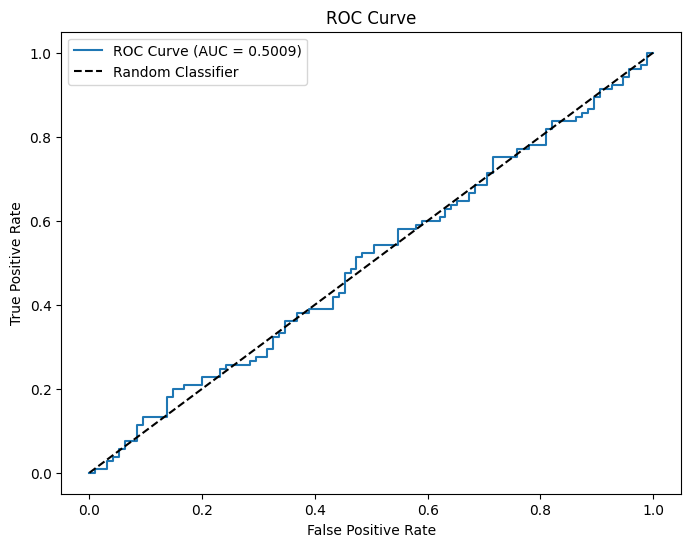

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, roc_curve

model.eval()

with torch.no_grad():
    test_preds_prob = model(X_test_tensor).cpu().numpy()
    test_preds_labs = (test_preds_prob > 0.5).astype(int)
    y_test_np = y_test_tensor.cpu().numpy()
print("--- Classification Report ---")
print(classification_report(y_test_np, test_preds_labs))

print("\n--- Confusion Matrix ---")
cm = confusion_matrix(y_test_np, test_preds_labs)
print(cm)

roc_auc = roc_auc_score(y_test_np, test_preds_prob)
print(f"\nROC-AUC Score: {roc_auc:.4f}")

fpr, tpr, thresholds = roc_curve(y_test_np, test_preds_prob)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [13]:
model_path = 'loaded_model_weight.pth'
torch.save(model.state_dict(),model_path)
print(f"Model weights successfully saved to '{model_path}'")

input_dim = X_train.shape[1]
loaded_model = LogisticRegressionModel(input_dim)
loaded_model.load_state_dict(torch.load(model_path))
loaded_model.eval()
print("Model weights loaded into new instance and set to evaluation mode!\n")

with torch.no_grad():
    loaded_test_preds = loaded_model(X_test_tensor)
    loaded_pred_labels = (loaded_test_preds >= 0.5).float()
    loaded_test_accuracy = (loaded_pred_labels == y_test_tensor).float().mean().item()

print(f"Original Model Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Loaded Model Test Accuracy:   {loaded_test_accuracy * 100:.2f}%")

Model weights successfully saved to 'loaded_model_weight.pth'
Model weights loaded into new instance and set to evaluation mode!

Original Model Test Accuracy: 50.50%
Loaded Model Test Accuracy:   50.50%


In [14]:
import torch
import torch.nn as nn
import torch.optim as optim

learning_rate = [0.01,0.05,0.1]
epochs = 100

best_lr = None
best_accuracy = 0.0
result = {}

input_dim = X_train_tensor.shape[1]
criterion = nn.BCELoss()    

for lr in learning_rate:
    print(f"--- Testing Learning Rate: {lr} ---")

    model_tuned = LogisticRegressionModel(input_dim)
    optimizer = optim.SGD(model_tuned.parameters(), lr=lr)

    for epoch in range(epochs):
        optimizer.zero_grad()
        outputs= model_tuned(X_train_tensor)
        loss = criterion(outputs,y_train_tensor)
        loss.backward()
        optimizer.step()

    model_tuned.eval()
    with torch.no_grad():
        test_preds = model_tuned(X_test_tensor)
        test_pred_labs = (test_preds >= 0.5).float()
        test_pred_accuracy = (test_pred_labs == y_test_tensor).float().mean().item()

    result[lr] = test_pred_accuracy
    print(f"Learning Rate {lr} -> Test Accuracy: {test_pred_accuracy * 100:.2f}%\n")

    if test_pred_accuracy > best_accuracy:
        best_accuracy = test_pred_accuracy
        best_lr = lr

print(f"Best Learning Rate: {best_lr} -> Best Test Accuracy: {best_accuracy * 100:.2f}%")

    

--- Testing Learning Rate: 0.01 ---
Learning Rate 0.01 -> Test Accuracy: 45.50%

--- Testing Learning Rate: 0.05 ---
Learning Rate 0.05 -> Test Accuracy: 52.00%

--- Testing Learning Rate: 0.1 ---
Learning Rate 0.1 -> Test Accuracy: 51.00%

Best Learning Rate: 0.05 -> Best Test Accuracy: 52.00%


--- Feature Importance Ranking ---
        feature  importance
3   gold_earned    0.168540
0         kills    0.126118
5  wards_placed    0.102142
1        deaths   -0.004460
4            cs   -0.007077
2       assists   -0.012994
7  damage_dealt   -0.017638
6  wards_killed   -0.032611


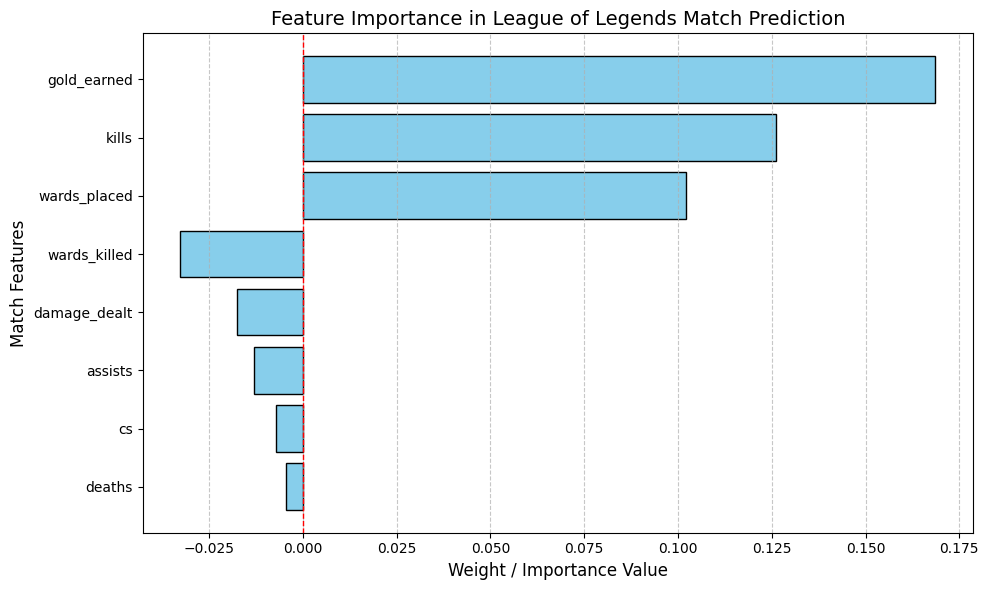

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

weights = model.linear.weight.data.cpu().numpy().flatten()
features = X.columns

feature_importance = pd.DataFrame({
    "feature": features,
    "importance": weights
})

feature_importance['Abs_Importance'] = feature_importance['importance'].abs()
feature_importance = feature_importance.sort_values(by='Abs_Importance', ascending=True)

print("--- Feature Importance Ranking ---")
print(feature_importance[['feature', 'importance']].sort_values(by='importance', ascending=False))

plt.figure(figsize=(10, 6))
plt.barh(feature_importance['feature'], feature_importance['importance'], color='skyblue', edgecolor='black')
plt.axvline(0, color='red', linestyle='--', linewidth=1)
plt.xlabel('Weight / Importance Value', fontsize=12)
plt.ylabel('Match Features', fontsize=12)
plt.title('Feature Importance in League of Legends Match Prediction', fontsize=14)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()